In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [2]:
path = '/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/Waves_2023.txt'
waves = pd.read_csv(path, sep=r"\s+")
waves

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
0,2023,1,1,0,26,999,99.0,99.0,1.12,12.50,7.69,269,9999.0,999.0,15.3,999.0,99.0,99.0
1,2023,1,1,0,56,999,99.0,99.0,1.16,11.76,7.34,272,9999.0,999.0,15.3,999.0,99.0,99.0
2,2023,1,1,1,26,999,99.0,99.0,1.20,12.50,7.08,268,9999.0,999.0,15.3,999.0,99.0,99.0
3,2023,1,1,1,56,999,99.0,99.0,1.25,10.53,7.33,268,9999.0,999.0,15.4,999.0,99.0,99.0
4,2023,1,1,2,26,999,99.0,99.0,1.27,10.53,7.57,268,9999.0,999.0,15.5,999.0,99.0,99.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17280,2023,12,31,21,56,999,99.0,99.0,2.01,14.29,11.19,270,9999.0,999.0,16.7,999.0,99.0,99.0
17281,2023,12,31,22,26,999,99.0,99.0,1.75,15.38,10.37,267,9999.0,999.0,16.7,999.0,99.0,99.0
17282,2023,12,31,22,56,999,99.0,99.0,1.79,13.33,10.50,268,9999.0,999.0,16.8,999.0,99.0,99.0
17283,2023,12,31,23,26,999,99.0,99.0,1.66,14.29,10.32,271,9999.0,999.0,16.8,999.0,99.0,99.0


In [3]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [4]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [5]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

In [6]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy() # dropping our target
df_y = wavesML['WVHT'].to_numpy() # what we ar predicting, what we removed from above

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10) # making training and test data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10) # taking 10% of the training data and setting it aside for validation data

In [7]:
from sklearn.ensemble import RandomForestRegressor
regRF = RandomForestRegressor(n_estimators=100)
regRF = regRF.fit(X_train, y_train)
yPred = regRF.predict(X_val) # use the validation data to predict. the train data was used for the model to learn the relationships between predictors and what you are trying to predict 

y_pred_train = regRF.predict(X_train)
train_mse = mean_squared_error(y_train, y_pred_train)
print("Train MSE: ", train_mse)

mean_squared_error(yPred,y_val)
print("Validation MSE: ", mean_squared_error(yPred,y_val))

Train MSE:  0.011039346993129272
Validation MSE:  0.09011440919781075


In [8]:
y_pred_test = regRF.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred_test)
print("Test MSE: ", test_mse)

Test MSE:  0.0714932136501779


# linear model

In [9]:
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_val)
mean_squared_error(y_val, y_pred)
print("Linear Reg MSE: ", mean_squared_error(y_val, y_pred))

Linear Reg MSE:  0.217012637278369


It seems like the RandomForestRegressor was better than the linear regression based on the lower MSE

Cost function: MSE

Hyperparameters: I think I only optimized the number of trees for this Random Forest

In [11]:
# changing the training data to 20%

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.3) # making training and test data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10) # taking 10% of the training data and setting it aside for validation data

from sklearn.ensemble import RandomForestRegressor
regRF = RandomForestRegressor(n_estimators=100)
regRF = regRF.fit(X_train, y_train)
yPred = regRF.predict(X_val) # use the validation data to predict. the train data was used for the model to learn the relationships between predictors and what you are trying to predict 

y_pred_train = regRF.predict(X_train)
train_mse = mean_squared_error(y_train, y_pred_train)
print("Train2 MSE: ", train_mse)

mean_squared_error(yPred,y_val)
print("Validation2 MSE: ", mean_squared_error(yPred,y_val))

y_pred_test = regRF.predict(X_test)
test_mse = mean_squared_error(y_test, y_pred_test)
print("Test2 MSE: ", test_mse)

Train2 MSE:  0.011465788959550707
Validation2 MSE:  0.0775171698158035
Test2 MSE:  0.08186473210887697


I think the answers I get from changing the train test split are pretty similar. 

Text(0.5, 1.0, 'Random Forest Training Error')

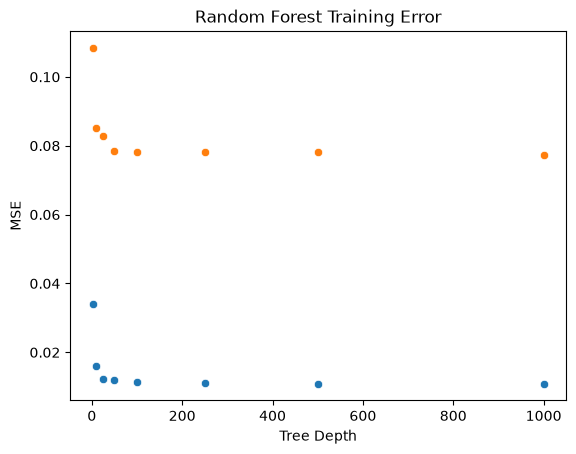

In [13]:
tree_n = [2, 10, 25, 50, 100,
250, 500,1000]
scores = []
val_scores = []

for tree in tree_n:
    model = RandomForestRegressor(n_estimators=tree)
    model.fit(X_train, y_train)

    train_mse = mean_squared_error(y_train, model.predict(X_train))
    scores.append(train_mse)

    val_scores.append(mean_squared_error(y_val, model.predict(X_val)))

    
sns.scatterplot(x=tree_n,y=scores)
sns.scatterplot(x=tree_n,y=val_scores)

plt.xlabel("Tree Depth")
plt.ylabel("MSE")
plt.title("Random Forest Training Error")

It seems that there is a benefit of having a trees around n=25 since the errors of both the validation and the test drop, but then it stays constant which makes me think that adding more trees to the model doesn't help the overall performance. 

The MSE for training data is much less than the validation data, maybe showing that the training data is overfitted in general. But increasing the number of trees to 1000 does not seem to have a different error than n=500 trees, so I don't think there is specific overfitting at n=1000 trees